# İstanbul'da İlçelerin Raylı Sistem Erişimi

**Araştırma sorusu:** İstanbul'da raylı sistem istasyonlarının ilçelere dağılımı, ilçelerin nüfusu ile orantılı mıdır?

Bu not defteri şunları yapıyor:

1. İBB istasyon verisini okuyor
2. Veriyi temizliyor (aynı istasyonun farklı yazımlarını birleştiriyor)
3. Her ilçedeki istasyonu sayıp TÜİK nüfusuyla birleştiriyor
4. Betimsel istatistikleri ve grafikleri üretiyor (alt problem 1 ve 2)
5. H1'i sınıyor: nüfus ile istasyon sayısı arasında ilişki var mı?
6. H2'yi sınıyor: iki yaka arasında fark var mı?

**Nasıl çalıştırılır?** Google Colab'da üst menüden Çalışma zamanı > Tümünü çalıştır deyin. İlk hücre sizden iki dosya isteyecek: İBB istasyon dosyası ve `ilce_nufus.csv`.

## Adım 0: Dosyaları hazırla

In [1]:
import os

# Colab'da dosyaları elle yüklüyorum, kendi bilgisayarımda ise depodaki yollardan okuyorum.
try:
    from google.colab import files
    COLAB = True
except ImportError:
    COLAB = False

if COLAB:
    print("1) İBB'den indirdiğiniz istasyon dosyasını seçin")
    secilen = files.upload()
    ISTASYON_DOSYASI = list(secilen.keys())[0]
    print("2) ilce_nufus.csv dosyasını seçin")
    secilen = files.upload()
    NUFUS_DOSYASI = list(secilen.keys())[0]
    KOK = "."
else:
    KOK = ".."  # not defteri analiz/ klasöründe, depo kökü bir üstte
    ISTASYON_DOSYASI = KOK + "/veri/ham/istasyon_verisi.csv"
    NUFUS_DOSYASI = KOK + "/veri/ilce_nufus.csv"

os.makedirs(KOK + "/veri/islenmis", exist_ok=True)
os.makedirs(KOK + "/rapor/sekiller", exist_ok=True)

print("İstasyon dosyası:", ISTASYON_DOSYASI)
print("Nüfus dosyası:", NUFUS_DOSYASI)

İstasyon dosyası: ../veri/ham/istasyon_verisi.csv
Nüfus dosyası: ../veri/ilce_nufus.csv


In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats

pd.set_option("display.max_rows", 50)

## Adım 1: İstasyon verisini oku

İBB dosyasında her satır bir istasyonun bir gündeki yolcu bilgisi. Yani aynı istasyon binlerce kez tekrar ediyor. Bana sadece istasyon adı ve ilçe lazım.

Dosyanın ayracı ve kodlaması indirilen sürüme göre değişebiliyor, o yüzden birkaç seçeneği deniyorum.

In [3]:
def dosya_oku(yol):
    """CSV dosyasini okur. Ayrac ve kodlama degisebildigi icin birkac secenek dener."""
    for kodlama in ["utf-8-sig", "cp1254", "iso-8859-9"]:
        for ayrac in [";", ","]:
            try:
                tablo = pd.read_csv(yol, sep=ayrac, encoding=kodlama, low_memory=False)
            except Exception:
                continue
            if tablo.shape[1] > 1:
                print(f"Okundu. Kodlama: {kodlama}, ayrac: '{ayrac}'")
                return tablo
    raise ValueError("Dosya okunamadi. Ayraci ve kodlamayi kontrol edin.")


def sutun_bul(tablo, adaylar):
    """Sutun adlari dosyadan dosyaya degisiyor (STATION_NAME, station_name gibi)."""
    for sutun in tablo.columns:
        if str(sutun).strip().lower() in adaylar:
            return sutun
    raise KeyError(f"Su sutunlardan biri bulunamadi: {adaylar}")


istasyon_ham = dosya_oku(ISTASYON_DOSYASI)
print("Satır sayısı:", len(istasyon_ham))
print("Sütunlar:", list(istasyon_ham.columns))

SUTUN_ISTASYON = sutun_bul(istasyon_ham, {"station_name", "istasyon_adi", "istasyon", "durak_adi"})
SUTUN_ILCE = sutun_bul(istasyon_ham, {"town", "ilce", "ilçe", "district"})
SUTUN_HAT = sutun_bul(istasyon_ham, {"line", "hat", "hat_adi", "line_name"})
print("Kullanacağım sütunlar:", SUTUN_ISTASYON, ",", SUTUN_ILCE, "ve", SUTUN_HAT)

istasyon_ham.head()

Okundu. Kodlama: utf-8-sig, ayrac: ';'
Satır sayısı: 135783
Sütunlar: ['transaction_year', 'transaction_month', 'transaction_day', 'line', 'station_name', 'station_number', 'town', 'longitude', 'latitude', 'passage_cnt', 'passanger_cnt']
Kullanacağım sütunlar: station_name , town ve line


,transaction_year,transaction_month,transaction_day,line,station_name,station_number,town,longitude,latitude,passage_cnt,passanger_cnt
0,2025,5,26,TF2-TELEFERIK EYUP PIYERLOTI,Pierloti,PLT-EYU,EyüpSultan,289.335.555.555.556,410.533.333.333.333,1386,604
1,2025,9,1,TF2-TELEFERIK EYUP PIYERLOTI,Eyüp,EYU-PLT,EyüpSultan,289.343.888.888.889,410.498.333.333.333,2639,1439
2,2025,10,25,TF2-TELEFERIK EYUP PIYERLOTI,Pierloti,PLT-EYU,EyüpSultan,289.335.555.555.556,410.533.333.333.333,2476,1024
3,2025,12,14,TF2-TELEFERIK EYUP PIYERLOTI,Pierloti,PLT-EYU,EyüpSultan,289.335.555.555.556,410.533.333.333.333,1885,1099
4,2025,5,7,TF2-TELEFERIK EYUP PIYERLOTI,Pierloti,PLT-EYU,EyüpSultan,289.335.555.555.556,410.533.333.333.333,2056,1141


## Adım 2: Veriyi temizle

Dosyayı ilk açtığımda sayımı bozan üç şey gördüm:

1. **Aynı istasyon farklı adlarla yazılmış.** Marmaray'da `Sirkeci-1`, `Sirkeci-2`, `Sirkeci-3`, `Sirkeci-4` ayrı ayrı geçiyor. M7'de `MAHMUTBEY M7 HOL 1` ve `HOL 2` var. Bunlar aynı istasyonun farklı girişleri.
2. **Aynı istasyon farklı ilçelere yazılmış.** Örneğin `MAHMUTBEY M7 HOL 1` hem Bağcılar hem Esenyurt hem Fatih olarak kaydedilmiş. Bu, veri girişi hatası gibi duruyor.
3. **İlçesi boş satırlar var.**

Düzeltmezsem Fatih gibi aktarma istasyonu çok olan ilçeler olduğundan fazla istasyonlu görünüyor.

Çözümüm:

- İstasyon adını büyük harfe çeviriyorum, fazla boşlukları atıyorum, sondaki `-1`, `-2` ve `HOL 1` gibi ekleri siliyorum.
- Bir istasyon birden fazla ilçeyle kaydedildiyse, en çok hangi ilçeyle geçiyorsa o ilçeye sayıyorum.
- Adı ya da ilçesi boş olan satırları atıyorum.

In [4]:
def istasyon_adi_duzelt(ad):
    """Ayni istasyonun farkli yazimlarini tek bir ada indirger."""
    s = " ".join(str(ad).split())            # bastaki, sondaki ve fazla bosluklari at
    s = s.replace("i", "İ").replace("ı", "I")  # Turkce buyuk harf duzgun olsun diye
    s = s.upper()
    s = re.sub(r"\s*HOL\s*\d+$", "", s)     # "MAHMUTBEY M7 HOL 1" -> "MAHMUTBEY M7"
    s = re.sub(r"-\s*\d+$", "", s)           # "SİRKECİ-1" -> "SİRKECİ"
    return s.strip()


istasyonlar = istasyon_ham[[SUTUN_ISTASYON, SUTUN_ILCE, SUTUN_HAT]].copy()
istasyonlar.columns = ["istasyon", "ilce", "hat"]
istasyonlar["istasyon"] = istasyonlar["istasyon"].fillna("").astype(str).str.strip()
istasyonlar["ilce"] = istasyonlar["ilce"].fillna("").astype(str).str.strip()
istasyonlar["hat"] = istasyonlar["hat"].fillna("").astype(str).str.strip()

bos_satir = (istasyonlar["istasyon"] == "") | (istasyonlar["ilce"] == "")
print("Adı ya da ilçesi boş olduğu için atılan satır:", int(bos_satir.sum()))
istasyonlar = istasyonlar[~bos_satir].copy()

istasyonlar["istasyon_temiz"] = istasyonlar["istasyon"].apply(istasyon_adi_duzelt)

print("Temizlemeden önce farklı istasyon adı:", istasyonlar["istasyon"].nunique())
print("Temizlemeden sonra farklı istasyon adı:", istasyonlar["istasyon_temiz"].nunique())

Adı ya da ilçesi boş olduğu için atılan satır: 1144
Temizlemeden önce farklı istasyon adı: 345
Temizlemeden sonra farklı istasyon adı: 309


In [5]:
# Hangi adlar birlestirildi? Raporda yazmak icin listeliyorum.
birlesenler = (
    istasyonlar.groupby("istasyon_temiz")["istasyon"]
    .unique()
)
birlesenler = birlesenler[birlesenler.apply(len) > 1]

print("Birleştirilen istasyon sayısı:", len(birlesenler))
for temiz_ad, eski_adlar in birlesenler.items():
    print(f"  {temiz_ad}  <-  {', '.join(sorted(eski_adlar))}")

Birleştirilen istasyon sayısı: 19
  ATAKÖY  <-  ATAKÖY, Ataköy
  BAKIRKÖY  <-  Bakırköy, Bakırköy-1, Bakırköy-2
  BOSTANCI  <-  BOSTANCI, Bostancı, Bostancı-1, Bostancı-2
  CEVİZLİ  <-  Cevizli-1, Cevizli-2
  DUDULLU  <-  DUDULLU, Dudullu
  GAYRETTEPE  <-  GAYRETTEPE, Gayrettepe
  GEBZE  <-  Gebze-1, Gebze-2
  KAZLIÇEŞME  <-  KAZLIÇEŞME, Kazlıçeşme
  KOZYATAĞI  <-  KOZYATAĞI, Kozyatağı
  KÜÇÜKYALI  <-  Küçükyalı, Küçükyalı-1, Küçükyalı-2
  MAHMUTBEY M3  <-  MAHMUTBEY M3 HOL 3, MAHMUTBEY M3 HOL 4
  MAHMUTBEY M7  <-  MAHMUTBEY M7 HOL 1, MAHMUTBEY M7 HOL 2, Mahmutbey M7 Hol 1, Mahmutbey M7 Hol 2, Mahmutbey M7 Hol 3, Mahmutbey M7 Hol 4
  SİRKECİ  <-  Sirkeci, Sirkeci-1, Sirkeci-2, Sirkeci-3, Sirkeci-4, SİRKECİ
  TERSANE  <-  Tersane-1, Tersane-2
  YENİBOSNA  <-  YENİBOSNA, Yenibosna
  YENİKAPI  <-  YENİKAPI, Yenikapı, Yenikapı-1, Yenikapı-2, Yenikapı-3
  YENİMAHALLE  <-  YENİMAHALLE, Yenimahalle
  ÜSKÜDAR  <-  Üsküdar, Üsküdar-1, Üsküdar-2, Üsküdar-3
  İKİTELLİ SANAYİ  <-  İKİTELLİ SANAYİ,

In [6]:
# Bir istasyon birden fazla ilceyle kaydedilmisse, varsayilan olarak en cok gectigi
# ilceye sayiyorum. Ama bu kural her zaman dogru sonuc vermiyor: ayni istasyonun
# farkli yazimlari satir sayisini sisirebiliyor. O yuzden bu istasyonlari asagida
# tek tek listeliyorum ve İBB hat haritasindan kontrol ediyorum.
# Kontrol ettigim istasyonun dogru ilcesini asagidaki sozluge yaziyorum.
ELLE_DUZELTME = {
    # "MAHMUTBEY M7": "Bağcılar",
}

satir_sayisi = (
    istasyonlar.groupby(["istasyon_temiz", "ilce"])
    .size()
    .reset_index(name="satir")
    .sort_values(["satir", "ilce"], ascending=[False, True])
)

coklu = satir_sayisi.groupby("istasyon_temiz").size()
coklu = coklu[coklu > 1]
print("Birden fazla ilçeye kaydedilmiş istasyon sayısı:", len(coklu))
print("Bunları İBB hat haritasından kontrol etmem gerekiyor.")
print()
for ad in sorted(coklu.index):
    secenekler = satir_sayisi[satir_sayisi["istasyon_temiz"] == ad]
    hepsi = ", ".join(f"{r.ilce} ({r.satir} satır)" for r in secenekler.itertuples())
    if ad in ELLE_DUZELTME:
        print(f"  {ad}: {hepsi}  ->  {ELLE_DUZELTME[ad]} (elle düzeltildi)")
    else:
        print(f"  {ad}: {hepsi}  ->  {secenekler.iloc[0]['ilce']} (en çok geçen, KONTROL EDİLECEK)")

istasyon_ilce = satir_sayisi.drop_duplicates("istasyon_temiz")[["istasyon_temiz", "ilce"]].copy()
istasyon_ilce["ilce"] = [
    ELLE_DUZELTME.get(ad, ilce)
    for ad, ilce in zip(istasyon_ilce["istasyon_temiz"], istasyon_ilce["ilce"])
]
print()
print("Temizlik sonrası toplam istasyon sayısı:", len(istasyon_ilce))

Birden fazla ilçeye kaydedilmiş istasyon sayısı: 13
Bunları İBB hat haritasından kontrol etmem gerekiyor.

  BOSTANCI: Kadıköy (1095 satır), Maltepe (365 satır)  ->  Kadıköy (en çok geçen, KONTROL EDİLECEK)
  GAYRETTEPE: Şişli (519 satır), Beşiktaş (365 satır)  ->  Şişli (en çok geçen, KONTROL EDİLECEK)
  GEBZE: Darıca (365 satır), Gebze (365 satır)  ->  Darıca (en çok geçen, KONTROL EDİLECEK)
  GÖZTEPE: Kadıköy (365 satır), Üsküdar (365 satır)  ->  Kadıköy (en çok geçen, KONTROL EDİLECEK)
  HALKALI: Bakırköy (365 satır), Küçükçekmece (365 satır)  ->  Bakırköy (en çok geçen, KONTROL EDİLECEK)
  KAZLIÇEŞME: Fatih (365 satır), Zeytinburnu (365 satır)  ->  Fatih (en çok geçen, KONTROL EDİLECEK)
  KOZYATAĞI: Ataşehir (365 satır), Kadıköy (365 satır)  ->  Ataşehir (en çok geçen, KONTROL EDİLECEK)
  MAHMUTBEY M7: Güngören (1460 satır), Bağcılar (1095 satır), Beylikdüzü (365 satır), Esenyurt (365 satır), Fatih (365 satır)  ->  Güngören (en çok geçen, KONTROL EDİLECEK)
  SAĞMALCILAR: Bayrampaş

## Adım 3: İlçelere göre say ve nüfusla birleştir

İlçe adları iki dosyada farklı yazılmış olabiliyor (ŞİŞLİ, Şişli, EyüpSultan gibi). Karşılaştırabilmek için her ilçe adını sadeleştirilmiş küçük harfli bir anahtara çeviriyorum.

In [7]:
def ilce_anahtari(ad):
    """Ilce adlarini karsilastirmak icin sadelestirir: 'EyüpSultan' -> 'eyupsultan'."""
    donusum = str.maketrans("İIıŞşĞğÜüÖöÇç", "iiissgguuoocc")
    return str(ad).strip().translate(donusum).lower().replace(" ", "")


istasyon_ilce = istasyon_ilce.copy()
istasyon_ilce["anahtar"] = istasyon_ilce["ilce"].apply(ilce_anahtari)

ilce_sayim = (
    istasyon_ilce.groupby("anahtar")
    .size()
    .reset_index(name="istasyon_sayisi")
)

nufus = pd.read_csv(NUFUS_DOSYASI)
if nufus["nufus"].isna().any():
    eksik = nufus.loc[nufus["nufus"].isna(), "ilce"].tolist()
    raise ValueError(f"Nüfusu girilmemiş ilçeler var: {eksik}")
nufus["anahtar"] = nufus["ilce"].apply(ilce_anahtari)

# Nufus tablosunda olmayan ilceler = Istanbul disi. Bunlari rapora yazacagim.
istanbul_disi = set(ilce_sayim["anahtar"]) - set(nufus["anahtar"])
if istanbul_disi:
    disarida = istasyon_ilce[istasyon_ilce["anahtar"].isin(istanbul_disi)]
    print("İstanbul dışında kaldığı için analize alınmayan ilçeler ve istasyonları:")
    for ilce_adi, grup in disarida.groupby("ilce"):
        print(f"  {ilce_adi}: {', '.join(sorted(grup['istasyon_temiz']))}")
else:
    print("İstanbul dışı ilçe bulunmadı.")

İstanbul dışında kaldığı için analize alınmayan ilçeler ve istasyonları:
  Darıca: DARICA, GEBZE, OSMANGAZİ
  Gebze: FATİH
  Çayırova: ÇAYIROVA


In [8]:
veri = nufus.merge(ilce_sayim, on="anahtar", how="left")
veri["istasyon_sayisi"] = veri["istasyon_sayisi"].fillna(0).astype(int)
veri["istasyon_100bin"] = veri["istasyon_sayisi"] / veri["nufus"] * 100_000
veri = veri.drop(columns="anahtar").sort_values("istasyon_100bin", ascending=False).reset_index(drop=True)

print("İlçe sayısı:", len(veri))
print("Analize giren toplam istasyon:", veri["istasyon_sayisi"].sum())
veri.round(2)

İlçe sayısı: 39
Analize giren toplam istasyon: 304


,ilce,yaka,nufus,istasyon_sayisi,istasyon_100bin
0,Fatih,Avrupa,351786,43,12.22
1,Bakırköy,Avrupa,218204,18,8.25
2,Şişli,Avrupa,261959,16,6.11
3,Eyüpsultan,Avrupa,425216,20,4.70
4,Beyoğlu,Avrupa,215991,10,4.63
5,Güngören,Avrupa,251242,10,3.98
6,Kadıköy,Anadolu,458573,17,3.71
7,Beşiktaş,Avrupa,165895,6,3.62
8,Sarıyer,Avrupa,344883,9,2.61
9,Bağcılar,Avrupa,707635,18,2.54


## Adım 4: Betimsel istatistik (alt problem 1 ve 2)

- **Alt problem 1:** İlçelerde istasyon sayısı ve 100.000 kişiye düşen istasyon sayısı nedir?
- **Alt problem 2:** Erişimi en yüksek ve en düşük olan ilçeler hangileri?

In [9]:
print("BETİMSEL İSTATİSTİKLER")
print(veri[["nufus", "istasyon_sayisi", "istasyon_100bin"]].describe().round(2))

print()
print("Hiç istasyonu olmayan ilçe sayısı:", int((veri["istasyon_sayisi"] == 0).sum()))
print("Bu ilçeler:", ", ".join(veri.loc[veri["istasyon_sayisi"] == 0, "ilce"]))

print()
print("ERİŞİMİ EN YÜKSEK 5 İLÇE")
print(veri[["ilce", "yaka", "nufus", "istasyon_sayisi", "istasyon_100bin"]].head(5).round(2).to_string(index=False))

print()
print("EN ÇOK İSTASYONU OLAN 5 İLÇE")
print(veri.sort_values("istasyon_sayisi", ascending=False)[["ilce", "yaka", "nufus", "istasyon_sayisi", "istasyon_100bin"]].head(5).round(2).to_string(index=False))

BETİMSEL İSTATİSTİKLER
            nufus  istasyon_sayisi  istasyon_100bin
count       39.00            39.00            39.00
mean    403950.08             7.79             2.09
std     205501.12             8.22             2.49
min      17489.00             0.00             0.00
25%     267468.50             1.00             0.32
50%     412125.00             6.00             1.60
75%     510897.00            11.00             2.53
max    1003905.00            43.00            12.22

Hiç istasyonu olmayan ilçe sayısı: 10
Bu ilçeler: Çatalca, Şile, Beykoz, Silivri, Beylikdüzü, Sultanbeyli, Büyükçekmece, Esenyurt, Avcılar, Adalar

ERİŞİMİ EN YÜKSEK 5 İLÇE
      ilce   yaka  nufus  istasyon_sayisi  istasyon_100bin
     Fatih Avrupa 351786               43            12.22
  Bakırköy Avrupa 218204               18             8.25
     Şişli Avrupa 261959               16             6.11
Eyüpsultan Avrupa 425216               20             4.70
   Beyoğlu Avrupa 215991               1

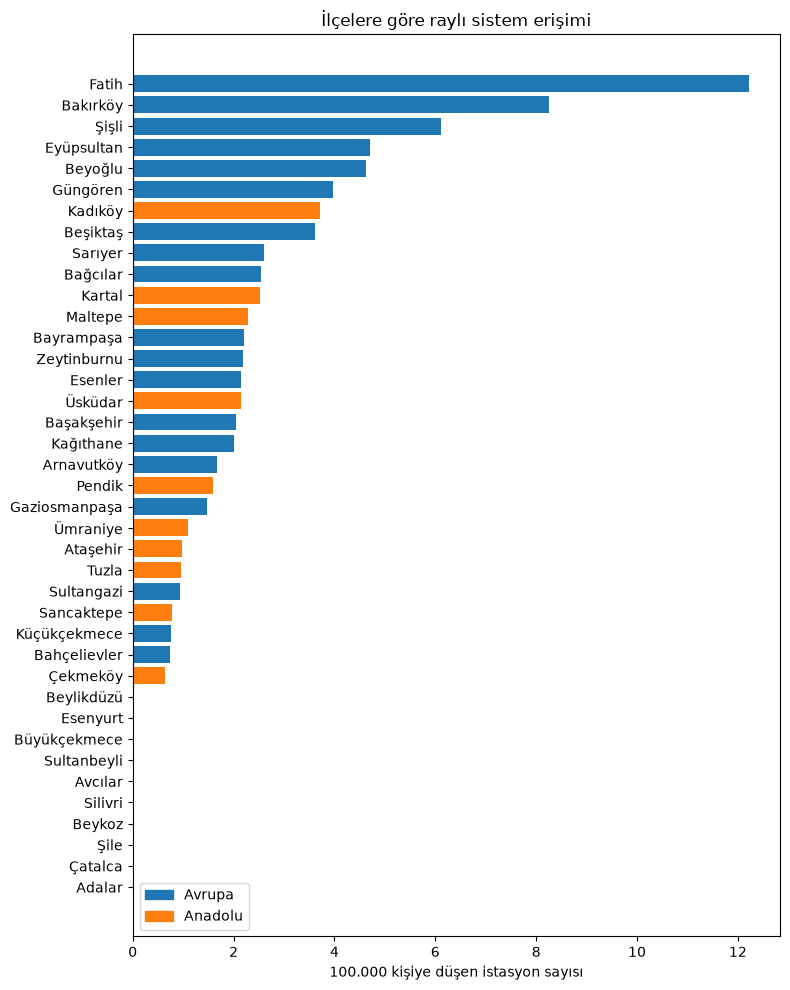

In [10]:
# Sekil 1: 39 ilcede 100.000 kisiye dusen istasyon sayisi
grafik_veri = veri.sort_values("istasyon_100bin")
renkler = ["tab:blue" if y == "Avrupa" else "tab:orange" for y in grafik_veri["yaka"]]

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(grafik_veri["ilce"], grafik_veri["istasyon_100bin"], color=renkler)
ax.set_xlabel("100.000 kişiye düşen istasyon sayısı")
ax.set_title("İlçelere göre raylı sistem erişimi")
# Renklerin neyi anlattigini gosteren kucuk kutu
ax.legend(handles=[Patch(color="tab:blue", label="Avrupa"),
                   Patch(color="tab:orange", label="Anadolu")])
plt.tight_layout()
plt.savefig(KOK + "/rapor/sekiller/sekil1_ilce_erisim.png", dpi=200)
plt.show()

## Adım 5: H1 (alt problem 3)

- **H1:** İlçe nüfusu arttıkça istasyon sayısı artar.
- **H0:** İlçe nüfusu ile istasyon sayısı arasında ilişki yoktur.

Korelasyon katsayısı (r) -1 ile +1 arasında bir sayı. +1'e yakınsa iki değişken birlikte artıyor, 0'a yakınsa aralarında ilişki yok. p değeri 0,05'ten küçükse bulunan ilişkinin tesadüf olma ihtimali düşük sayılıyor ve H0 reddediliyor.

Hem Pearson hem Spearman hesaplıyorum. Spearman sıralamaya baktığı için hiç istasyonu olmayan ilçeler gibi uç değerlerden daha az etkileniyor.

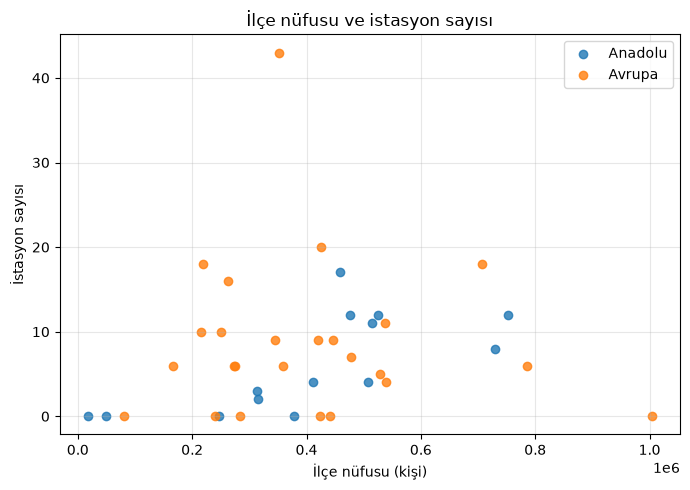

Pearson  r = 0.125, p = 0.4479
Spearman r = 0.267, p = 0.1008
Sonuç: H0 reddedilemedi. Anlamlı bir ilişki bulunamadı.


In [11]:
# Sekil 2: nufus ve istasyon sayisi
fig, ax = plt.subplots(figsize=(7, 5))
for yaka, grup in veri.groupby("yaka"):
    ax.scatter(grup["nufus"], grup["istasyon_sayisi"], label=yaka, alpha=0.8)
ax.set_xlabel("İlçe nüfusu (kişi)")
ax.set_ylabel("İstasyon sayısı")
ax.set_title("İlçe nüfusu ve istasyon sayısı")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(KOK + "/rapor/sekiller/sekil2_nufus_istasyon.png", dpi=200)
plt.show()

pearson_r, pearson_p = stats.pearsonr(veri["nufus"], veri["istasyon_sayisi"])
spearman_r, spearman_p = stats.spearmanr(veri["nufus"], veri["istasyon_sayisi"])

print(f"Pearson  r = {pearson_r:.3f}, p = {pearson_p:.4f}")
print(f"Spearman r = {spearman_r:.3f}, p = {spearman_p:.4f}")

if spearman_p < 0.05 and spearman_r > 0:
    print("Sonuç: H0 reddedildi. Nüfus arttıkça istasyon sayısı da artma eğiliminde.")
elif spearman_p < 0.05:
    print("Sonuç: Anlamlı bir ilişki var ama yönü beklediğimin tersi.")
else:
    print("Sonuç: H0 reddedilemedi. Anlamlı bir ilişki bulunamadı.")

## Adım 6: H2 (alt problem 4)

- **H2:** 100.000 kişiye düşen istasyon sayısı Avrupa ve Anadolu yakası arasında farklıdır.
- **H0:** İki yaka arasında fark yoktur.

Önce iki yakanın ortalama ve medyanına bakıyorum. Sonra Mann-Whitney U testi uyguluyorum. Bu test, grup sayıları küçük olduğunda ve veri normal dağılmadığında iki grubu karşılaştırmak için kullanılıyor. Burada veri normal dağılmıyor, çünkü birçok ilçede değer sıfır.

         ilçe sayısı  ortalama  medyan  en düşük  en yüksek
yaka                                                       
Anadolu           14      1.19    0.96       0.0       3.71
Avrupa            25      2.59    2.05       0.0      12.22


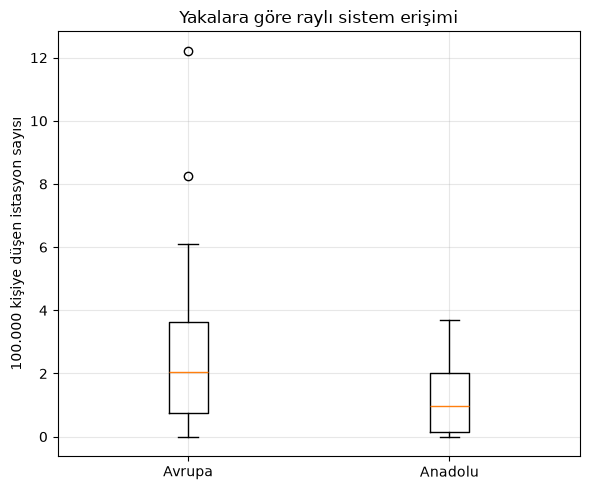


Mann-Whitney U = 223.0, p = 0.1608
Sonuç: H0 reddedilemedi. İki yaka arasında anlamlı fark bulunamadı.


In [12]:
ozet = veri.groupby("yaka")["istasyon_100bin"].agg(["count", "mean", "median", "min", "max"]).round(2)
ozet.columns = ["ilçe sayısı", "ortalama", "medyan", "en düşük", "en yüksek"]
print(ozet)

# Sekil 3: yakalara gore kutu grafigi
fig, ax = plt.subplots(figsize=(6, 5))
yakalar = ["Avrupa", "Anadolu"]
ax.boxplot([veri.loc[veri["yaka"] == y, "istasyon_100bin"] for y in yakalar])
ax.set_xticks([1, 2])
ax.set_xticklabels(yakalar)
ax.set_ylabel("100.000 kişiye düşen istasyon sayısı")
ax.set_title("Yakalara göre raylı sistem erişimi")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(KOK + "/rapor/sekiller/sekil3_yaka_karsilastirma.png", dpi=200)
plt.show()

avrupa = veri.loc[veri["yaka"] == "Avrupa", "istasyon_100bin"]
anadolu = veri.loc[veri["yaka"] == "Anadolu", "istasyon_100bin"]
u, p = stats.mannwhitneyu(avrupa, anadolu, alternative="two-sided")
print()
print(f"Mann-Whitney U = {u:.1f}, p = {p:.4f}")

if p < 0.05:
    print("Sonuç: H0 reddedildi. İki yaka arasında anlamlı fark var.")
else:
    print("Sonuç: H0 reddedilemedi. İki yaka arasında anlamlı fark bulunamadı.")

## Adım 7: Dağılım nüfusla orantılı mı? (problem cümlesinin doğrudan cevabı)

Burada bir eksiği düzeltiyorum. Problem cümlem "istasyonların dağılımı nüfusla **orantılı** mıdır?" diye soruyor. Ama Adım 5'teki korelasyon bundan daha zayıf bir soruyu cevaplıyor: "nüfus artarsa istasyon sayısı da artıyor mu?"

İkisi aynı şey değil. Örnek: A ilçesinin 100.000 kişisi ve 10 istasyonu, B ilçesinin 1.000.000 kişisi ve 11 istasyonu olsun. Nüfus arttıkça istasyon artıyor, yani korelasyon pozitif. Ama dağılım hiç orantılı değil.

**Tam orantı ne demek?** Eğer istasyonlar nüfusla tam orantılı dağılsaydı, 100.000 kişiye düşen istasyon sayısı bütün ilçelerde **aynı** olurdu. O hâlde orantılılığı ölçmenin yolu, bu sayının ilçeler arasında ne kadar değiştiğine bakmak.

Üç ölçü kullanıyorum:

1. **Değişim katsayısı (CV):** standart sapmanın ortalamaya oranı. 0 ise bütün ilçeler aynı.
2. **Gini katsayısı:** 0 ise tam orantılı dağılım, 1'e yaklaştıkça eşitsizlik artıyor.
3. **Lorenz eğrisi:** x ekseninde nüfusun birikimli payı, y ekseninde istasyonların birikimli payı. Köşegen tam orantıyı gösterir; eğri köşegenden ne kadar uzaksa dağılım o kadar dengesizdir.

Gini ve Lorenz'i literatürden aldım: Zhu ve Rui (2025) ile Li ve ark. (2025) raylı sistem erişiminin eşitliğini tam olarak bu iki ölçüyle değerlendiriyor.

Değişim katsayısı (CV) = 1.192
Gini katsayısı         = 0.520

Yorum için ölçek: Gini 0 ise dağılım nüfusla tam orantılı,
0,3'ün altı görece dengeli, 0,5'in üstü belirgin eşitsizlik sayılıyor.


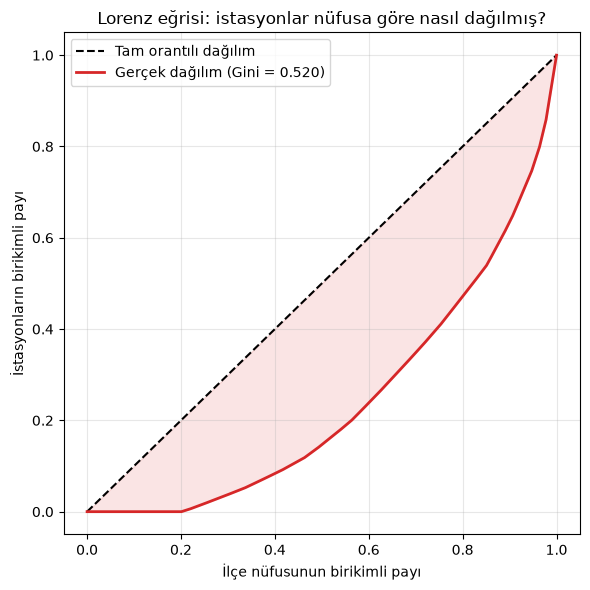


Erişimi en düşük ilçelerde yaşayan nüfusun yarısı, istasyonların yalnızca %14.7'ine sahip.


In [13]:
def lorenz_gini(nufus, istasyon):
    """Istasyonlarin nufusa gore ne kadar esit dagildigini olcer.
    0 = tam orantili dagilim, 1'e yaklastikca esitsizlik artar."""
    d = pd.DataFrame({"nufus": np.asarray(nufus, dtype=float),
                      "istasyon": np.asarray(istasyon, dtype=float)})
    # Ilceleri 100.000 kisiye dusen istasyon sayisina gore siraliyorum
    d["oran"] = d["istasyon"] / d["nufus"]
    d = d.sort_values("oran").reset_index(drop=True)
    x = np.concatenate([[0.0], (d["nufus"].cumsum() / d["nufus"].sum()).to_numpy()])
    y = np.concatenate([[0.0], (d["istasyon"].cumsum() / d["istasyon"].sum()).to_numpy()])
    alan = np.trapezoid(y, x) if hasattr(np, "trapezoid") else np.trapz(y, x)
    return 1 - 2 * alan, x, y


cv = veri["istasyon_100bin"].std() / veri["istasyon_100bin"].mean()
gini, lx, ly = lorenz_gini(veri["nufus"], veri["istasyon_sayisi"])

print(f"Değişim katsayısı (CV) = {cv:.3f}")
print(f"Gini katsayısı         = {gini:.3f}")
print()
print("Yorum için ölçek: Gini 0 ise dağılım nüfusla tam orantılı,")
print("0,3'ün altı görece dengeli, 0,5'in üstü belirgin eşitsizlik sayılıyor.")

# Sekil 4: Lorenz egrisi
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "k--", label="Tam orantılı dağılım")
ax.plot(lx, ly, color="tab:red", linewidth=2, label=f"Gerçek dağılım (Gini = {gini:.3f})")
ax.fill_between(lx, ly, lx, color="tab:red", alpha=0.12)
ax.set_xlabel("İlçe nüfusunun birikimli payı")
ax.set_ylabel("İstasyonların birikimli payı")
ax.set_title("Lorenz eğrisi: istasyonlar nüfusa göre nasıl dağılmış?")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(KOK + "/rapor/sekiller/sekil4_lorenz.png", dpi=200)
plt.show()

# Nufusun en az erisime sahip yarisi istasyonlarin yuzde kacina sahip?
yari = np.interp(0.5, lx, ly)
print(f"\nErişimi en düşük ilçelerde yaşayan nüfusun yarısı, istasyonların yalnızca "
      f"%{yari*100:.1f}'ine sahip.")

## Adım 8: Duyarlılık analizi

İki kararım sonucu etkiliyor olabilir. Sonucun bu kararlara ne kadar bağlı olduğunu görmek için ikisini de değiştirip tabloyu yeniden hesaplıyorum.

1. **Teleferik, füniküler, Tünel ve nostaljik tramvay.** İBB bunları raylı sistem sayıyor ama şehir içi ulaşımda metro gibi kullanılmıyorlar. Bunları çıkarınca ne oluyor?
2. **Birden fazla ilçeye kayıtlı 13 istasyon.** Şu an en çok geçtikleri ilçeye sayılıyorlar. Hiç saymazsam, yani en kötü durumda, sonuç ne kadar oynuyor?

Sonuçlar bu iki değişiklikte de aynı yönde kalıyorsa bulgularıma daha çok güvenebilirim.

In [14]:
def ilce_tablosu(istasyon_tablosu):
    """Temizlenmis istasyon satirlarindan ilce bazli sonuc tablosu uretir."""
    sayim = (
        istasyon_tablosu.groupby(["istasyon_temiz", "ilce"])
        .size().reset_index(name="satir")
        .sort_values(["satir", "ilce"], ascending=[False, True])
    )
    tek = sayim.drop_duplicates("istasyon_temiz")[["istasyon_temiz", "ilce"]].copy()
    tek["ilce"] = [ELLE_DUZELTME.get(a, i)
                   for a, i in zip(tek["istasyon_temiz"], tek["ilce"])]
    tek["anahtar"] = tek["ilce"].apply(ilce_anahtari)
    s = tek.groupby("anahtar").size().reset_index(name="istasyon_sayisi")
    t = nufus.merge(s, on="anahtar", how="left")
    t["istasyon_sayisi"] = t["istasyon_sayisi"].fillna(0).astype(int)
    t["istasyon_100bin"] = t["istasyon_sayisi"] / t["nufus"] * 100_000
    return t.drop(columns="anahtar")


def ozetle(t, ad):
    """Bir senaryonun temel sayilarini tek satirda dondurur."""
    g, _, _ = lorenz_gini(t["nufus"], t["istasyon_sayisi"])
    sr, sp = stats.spearmanr(t["nufus"], t["istasyon_sayisi"])
    av = t.loc[t["yaka"] == "Avrupa", "istasyon_100bin"]
    an = t.loc[t["yaka"] == "Anadolu", "istasyon_100bin"]
    _, mp = stats.mannwhitneyu(av, an, alternative="two-sided")
    return {"senaryo": ad,
            "istasyon": int(t["istasyon_sayisi"].sum()),
            "sıfır ilçe": int((t["istasyon_sayisi"] == 0).sum()),
            "Gini": round(g, 3),
            "Spearman r": round(sr, 3),
            "Spearman p": round(sp, 3),
            "Mann-Whitney p": round(mp, 3)}


# Hafif raylı sayilmayan hatlar
HARIC = ["TELEFERIK", "FUNIKILER", "FUNIKULER", "TUNEL", "NOSTALJIK"]
maske = istasyonlar["hat"].str.upper().apply(lambda h: any(k in h for k in HARIC))
print("Kapsam dışı bırakılan hatlar:")
for h in sorted(istasyonlar.loc[maske, "hat"].unique()):
    print("  ", h)

# 13 belirsiz istasyon
belirsiz = set(coklu.index)

senaryolar = [
    ozetle(veri, "1. Şu anki analiz (hepsi dahil)"),
    ozetle(ilce_tablosu(istasyonlar[~maske]), "2. Teleferik, füniküler, Tünel, nostaljik hariç"),
    ozetle(ilce_tablosu(istasyonlar[~istasyonlar["istasyon_temiz"].isin(belirsiz)]),
           "3. Belirsiz 13 istasyon hiç sayılmazsa"),
]
karsilastirma = pd.DataFrame(senaryolar)
print()
print(karsilastirma.to_string(index=False))

Kapsam dışı bırakılan hatlar:


   F1-TAKSIM-KABATAS FUNIKILER HATTI
   IETT TUNEL
   TF1-TELEFERIK MACKA - TASKISLA
   TF2-TELEFERIK EYUP PIYERLOTI

                                        senaryo  istasyon  sıfır ilçe  Gini  Spearman r  Spearman p  Mann-Whitney p
                1. Şu anki analiz (hepsi dahil)       304          10 0.520       0.267       0.101           0.161
2. Teleferik, füniküler, Tünel, nostaljik hariç       299          10 0.514       0.279       0.085           0.170
         3. Belirsiz 13 istasyon hiç sayılmazsa       292          10 0.517       0.272       0.093           0.144


## Adım 9: Sonuçları kaydet

In [15]:
cikti_yolu = KOK + "/veri/islenmis/ilce_erisim.csv"
veri.to_csv(cikti_yolu, index=False)
karsilastirma.to_csv(KOK + "/veri/islenmis/duyarlilik_analizi.csv", index=False)
print("Kaydedildi:", cikti_yolu)
print("Kaydedildi:", KOK + "/veri/islenmis/duyarlilik_analizi.csv")
print("Şekiller:", KOK + "/rapor/sekiller/ klasöründe")

# Colab'da calisiyorsam dosyalari bilgisayara indiriyorum.
if COLAB:
    for dosya in [cikti_yolu,
                  KOK + "/rapor/sekiller/sekil1_ilce_erisim.png",
                  KOK + "/rapor/sekiller/sekil2_nufus_istasyon.png",
                  KOK + "/rapor/sekiller/sekil3_yaka_karsilastirma.png",
                  KOK + "/rapor/sekiller/sekil4_lorenz.png"]:
        files.download(dosya)

Kaydedildi: ../veri/islenmis/ilce_erisim.csv
Kaydedildi: ../veri/islenmis/duyarlilik_analizi.csv
Şekiller: ../rapor/sekiller/ klasöründe


## Yorum (kendi cümlelerimle yazılacak)

Aşağıdaki soruları yukarıdaki çıktılara bakarak cevaplayacağım. Bu bölüm rapora girecek.

1. **Alt problem 1:** 100.000 kişiye ortalama kaç istasyon düşüyor? Kaç ilçede hiç istasyon yok?
2. **Alt problem 2:** Erişimi en yüksek ve en düşük ilçeler hangileri? Bunların ortak özelliği ne olabilir?
3. **Alt problem 3 (H1):** Korelasyon katsayısı ve p değeri ne çıktı? H1 desteklendi mi?
4. **Alt problem 4 (H2):** İki yakanın medyanı ne? Fark anlamlı mı?
5. **Dikkat:** Korelasyon nedensellik değildir. Nüfus ile istasyon sayısı birlikte artıyorsa bunu başka bir değişken, örneğin ilçenin şehir merkezine yakınlığı, açıklıyor olabilir mi?
6. **Veri temizliğinin etkisi:** Temizlik yapmasaydım hangi ilçelerin sayısı yanlış çıkacaktı?